In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="deep")

df = sns.load_dataset("tips")

print("Dataset loaded successfully!")
print("Shape:", df.shape)
df.head()

Dataset loaded successfully!
Shape: (244, 7)


,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


DATA QUALITY CHECK
----------------------------------------
Dataset shape: (244, 7)
Missing values: 0
Duplicate rows: 1


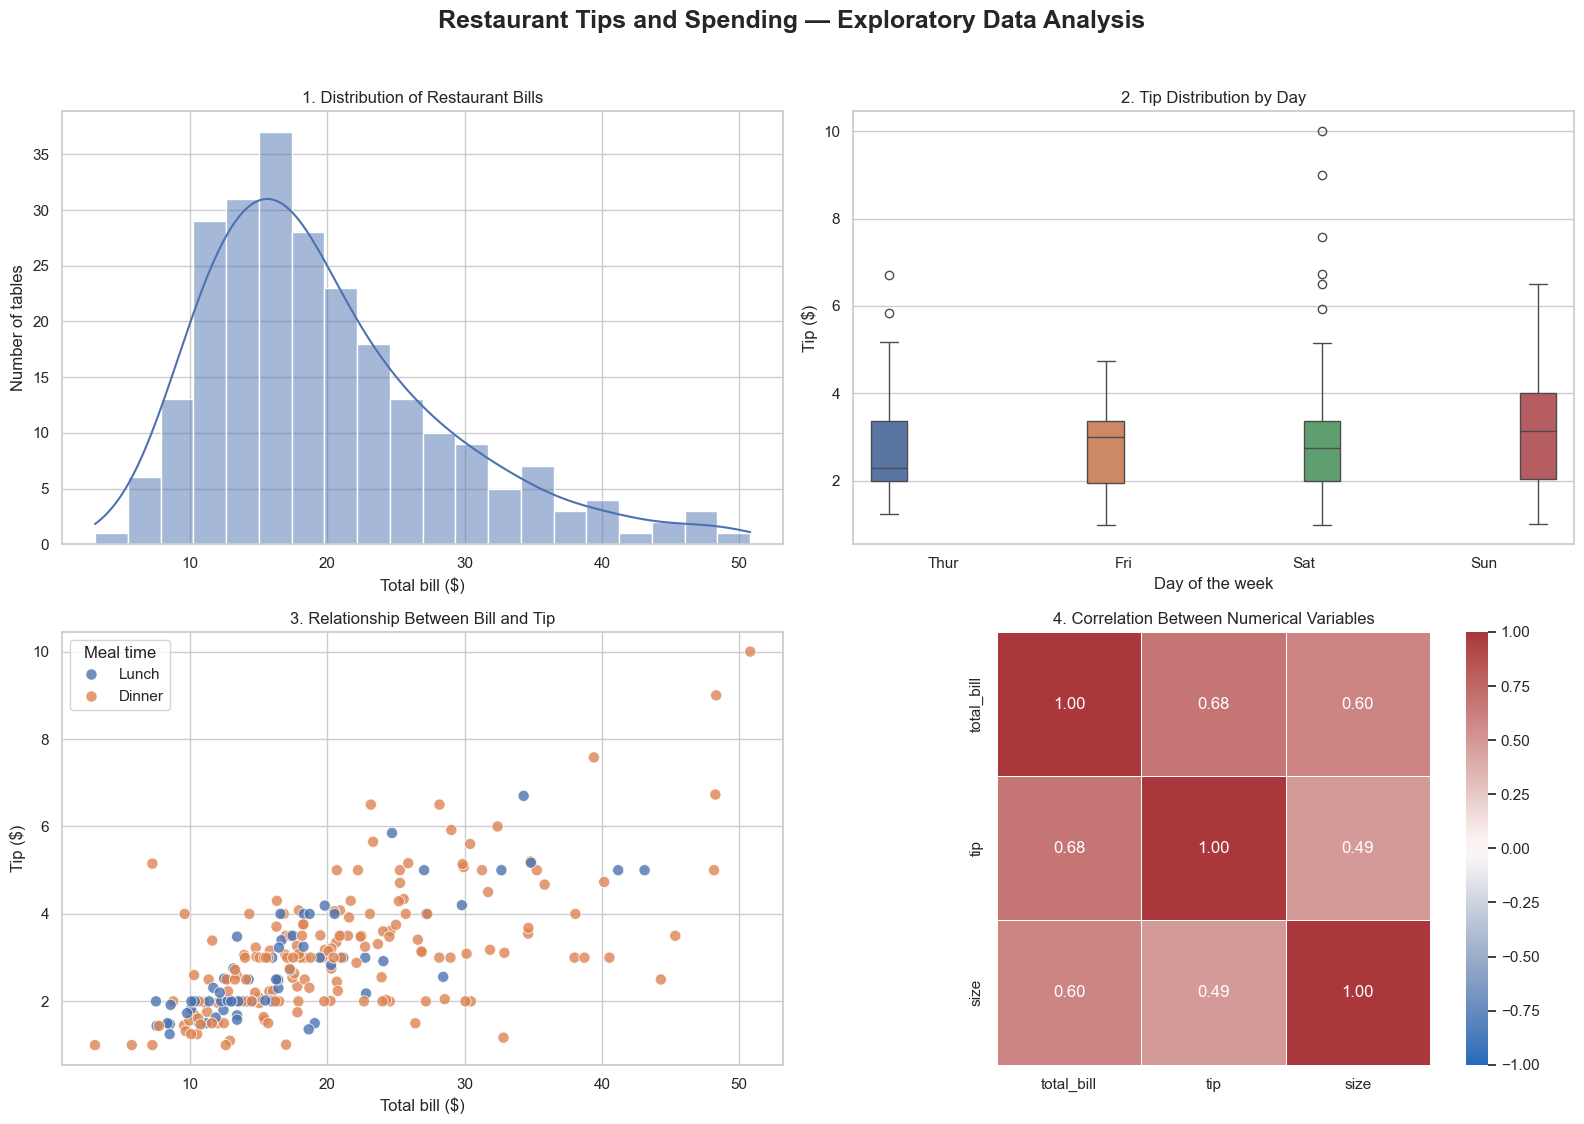


KEY FINDINGS
--------------------------------------------------
1. Bill distribution: Average bill = $19.79; median bill = $17.80.
2. Tips by day: Sun has the highest average tip ($3.26).
3. Bill and tip: Pearson correlation = 0.676.
4. Strongest numerical correlation: total_bill and tip (r = 0.676).

Dashboard saved as: tips_dashboard.png


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Consistent visualization theme
sns.set_theme(style="whitegrid", palette="deep")

# Check data quality
print("DATA QUALITY CHECK")
print("-" * 40)
print("Dataset shape:", df.shape)
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

# Calculate correlation matrix
numeric_df = df.select_dtypes(include="number")
corr = numeric_df.corr()

# Find strongest correlation between two distinct variables
upper_triangle = corr.where(
    np.triu(np.ones(corr.shape), k=1).astype(bool)
)
strongest_pair = upper_triangle.stack().abs().idxmax()
strongest_value = upper_triangle.loc[strongest_pair]

# Calculate actual findings
average_bill = df["total_bill"].mean()
median_bill = df["total_bill"].median()
average_tip = df["tip"].mean()

day_tips = df.groupby("day", observed=True)["tip"].mean()
highest_tip_day = day_tips.idxmax()
highest_tip_value = day_tips.max()

bill_tip_corr = df["total_bill"].corr(df["tip"])

# Create a 2 x 2 dashboard
fig, axes = plt.subplots(2, 2, figsize=(16, 11))

# Chart 1: Bill distribution
sns.histplot(
    data=df,
    x="total_bill",
    bins=20,
    kde=True,
    ax=axes[0, 0]
)

axes[0, 0].set_title("1. Distribution of Restaurant Bills")
axes[0, 0].set_xlabel("Total bill ($)")
axes[0, 0].set_ylabel("Number of tables")

# Chart 2: Tip variation by day
sns.boxplot(
    data=df,
    x="day",
    y="tip",
    hue="day",
    palette="deep",
    legend=False,
    ax=axes[0, 1]
)

axes[0, 1].set_title("2. Tip Distribution by Day")
axes[0, 1].set_xlabel("Day of the week")
axes[0, 1].set_ylabel("Tip ($)")

# Chart 3: Relationship between bill and tip
sns.scatterplot(
    data=df,
    x="total_bill",
    y="tip",
    hue="time",
    palette="deep",
    alpha=0.8,
    s=65,
    ax=axes[1, 0]
)

axes[1, 0].set_title("3. Relationship Between Bill and Tip")
axes[1, 0].set_xlabel("Total bill ($)")
axes[1, 0].set_ylabel("Tip ($)")
axes[1, 0].legend(title="Meal time")

# Chart 4: Correlation heatmap
sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="vlag",
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=0.5,
    ax=axes[1, 1]
)

axes[1, 1].set_title("4. Correlation Between Numerical Variables")

# Improve layout
fig.suptitle(
    "Restaurant Tips and Spending — Exploratory Data Analysis",
    fontsize=18,
    fontweight="bold",
    y=1.02
)

plt.tight_layout()

# Save dashboard
output_file = "tips_dashboard.png"
fig.savefig(output_file, dpi=150, bbox_inches="tight")

plt.show()

# Print data-driven takeaways
print("\nKEY FINDINGS")
print("-" * 50)

print(
    f"1. Bill distribution: Average bill = ${average_bill:.2f}; "
    f"median bill = ${median_bill:.2f}."
)

print(
    f"2. Tips by day: {highest_tip_day} has the highest "
    f"average tip (${highest_tip_value:.2f})."
)

print(
    f"3. Bill and tip: Pearson correlation = {bill_tip_corr:.3f}."
)

print(
    f"4. Strongest numerical correlation: "
    f"{strongest_pair[0]} and {strongest_pair[1]} "
    f"(r = {strongest_value:.3f})."
)

print(f"\nDashboard saved as: {output_file}")